## Análise de Imóveis
### Banco de dados: imoveis_sao_paulo.csv

### Objetivo: Distinguir ausência estrutural de ausência por falha de registro, imputar valores, medir erros, escalonar valores, reduzir assimetria, entender a diferença entre mudar a régua e a forma de uma distribuição

In [1]:
#Carregar as bibliotecas e o dataset que será utilizado:
import pandas as pd                 # tabelas (DataFrame): ler, limpar, agrupar
import numpy as np                  # cálculos numéricos (log, where, arrays)
import seaborn as sns               # gráficos estatísticos (boxplot, histplot...)
import matplotlib.pyplot as plt     # base dos gráficos (títulos, eixos, plt.show)
from scipy import stats             # testes estatísticos (ttest, mannwhitneyu, skew...)

from sklearn.preprocessing import (
    MinMaxScaler,                   # coloca os valores na faixa de 0 a 1 (mín vira 0, máx vira 1), usado quando precisa de limites fixos; sensível a outliers
    PowerTransformer,               # reduz a assimetria e deixa a distribuição mais parecida com a normal, usado em dados com cauda longa, como aluguel e condomínio
    RobustScaler,                   # centraliza na mediana e divide pelo IQR (Q3 - Q1), usado quando há outliers, porque não depende de média e desvio
    StandardScaler,                 # média 0 e desvio padrão 1 (z-score), usado em dados mais ou menos simétricos
)
#Estilo padrão dos gráficos:
sns.set_theme(style="whitegrid", palette="colorblind")
#Leitura do CSV:
imoveis = pd.read_csv("../data/imoveis_sao_paulo.csv")

## 0.   Ajustes Iniciais

In [2]:
#Leitura inicial do CSV:
imoveis.head(10)

,bairro,zona,tier,area,rooms,parking spaces,floor,total_floors,transit_distance_min,furniture,hoa (R$),rent amount (R$),property tax (R$),total (R$)
0,Santo Amaro,Zona Sul,mid,119.0,3,0.0,11.0,15.0,3,not furnished,NaN,5050.0,590.25,6910.0
1,Vila Mariana,Zona Sul,premium,97.9,3,1.0,15.0,25.0,10,not furnished,1072.0,5060.0,833.17,6970.0
2,Ipiranga,Zona Sul,mid,45.5,1,0.0,1.0,15.0,27,furnished,520.0,2470.0,283.92,3280.0
3,Raposo Tavares,Zona Oeste,mid,180.4,4,1.0,8.0,15.0,94,not furnished,2274.0,6270.0,775.17,9320.0
4,Brooklin,Zona Sul,luxury,36.1,0,1.0,2.0,8.0,1,not furnished,570.0,2960.0,330.00,3860.0
5,Itaquera,Zona Leste,affordable,97.3,3,1.0,6.0,15.0,2,not furnished,1306.0,1370.0,222.75,2900.0
6,Brooklin,Zona Sul,luxury,56.0,3,2.0,10.0,15.0,0,not furnished,1041.0,3260.0,476.50,4780.0
7,Brooklin,Zona Sul,luxury,100.9,3,3.0,4.0,8.0,70,furnished,1331.0,6080.0,855.50,8270.0
8,Limão,Zona Norte,mid,54.3,1,2.0,7.0,15.0,13,furnished,642.0,1320.0,214.75,2180.0
9,Jardim Europa,Zona Oeste,luxury,91.0,3,2.0,4.0,8.0,31,furnished,883.0,7570.0,895.00,9340.0


In [3]:
#Leitura geral:
imoveis.info()

<class 'pandas.DataFrame'>
RangeIndex: 29706 entries, 0 to 29705
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   bairro                29706 non-null  str    
 1   zona                  29706 non-null  str    
 2   tier                  29706 non-null  str    
 3   area                  29706 non-null  float64
 4   rooms                 29706 non-null  int64  
 5   parking spaces        29409 non-null  float64
 6   floor                 25252 non-null  float64
 7   total_floors          25252 non-null  float64
 8   transit_distance_min  29706 non-null  int64  
 9   furniture             29706 non-null  str    
 10  hoa (R$)              29201 non-null  float64
 11  rent amount (R$)      29706 non-null  float64
 12  property tax (R$)     29706 non-null  float64
 13  total (R$)            29706 non-null  float64
dtypes: float64(8), int64(2), str(4)
memory usage: 3.2 MB


In [4]:
imoveis.isna().sum()

bairro                     0
zona                       0
tier                       0
area                       0
rooms                      0
parking spaces           297
floor                   4454
total_floors            4454
transit_distance_min       0
furniture                  0
hoa (R$)                 505
rent amount (R$)           0
property tax (R$)          0
total (R$)                 0
dtype: int64

In [5]:
#Ajustes iniciais:
#Padronização das colunas:
colunas_novas = { #definir as antigas e novas em um dicinário já pronto pro rename
    "parking spaces" : "parking_spaces",
    "hoa (R$)" : "hoa",
    "rent amount (R$)" : "rent_amount",
    "property tax (R$)" : "property_tax",
    "total (R$)" : "total",
}

imoveis = ( #fazer uma cadeia de comandos
    imoveis                         #Mesma coisa que imoveis = imoveis...
    .rename(columns=colunas_novas)  #renomear as colunas antigas
    .drop_duplicates()              #retirar variaveis duplicadas
    .reset_index(drop=True)         #resetar o index da tabela para não ficar com buracos depois da retirada de duplicatas
    .assign(                        #função que adiciona colunas à tabela. O lambda recebe a tabela no ponto atual da cadeia
        property_type = lambda df: np.where(
            df["floor"].isna(),     #condição: onde o andar for nulo
            "casa",                 #valor se verdadeira
            "apartamento",          #valor se falsa
        )
    )
)

## 1.   Diagnóstico da distribuição
| Painel | Pergunta | O que observar |
|---|---|---|
| 1. Valores ausentes | Quais colunas têm lacunas, e em que proporção? | Se as proporções são parecidas ou se alguma coluna destoa das demais |
| 2. Escalas incompatíveis | As variáveis numéricas estão na mesma ordem de grandeza? | A distância entre as medianas de quartos, área e aluguel |
| 3. Cauda longa | Como os aluguéis se distribuem? | Onde se concentra a maioria dos imóveis e até onde a cauda se estende |

In [6]:
#Aqui vamos criar gráficos para visualizar as respostas
#1. Vamos definir os valores que são mostrados:
#% de valores ausentes (nulos) em cada coluna escolhida
porcentagem_faltantes = (
    imoveis[["hoa", "parking_spaces", "floor"]]    #seleciona 3 colunas
    .isna()                                         #True onde é nulo, False onde não é
    .mean()                                         #média de True/False = proporção de nulos
    .mul(100)                                       #multiplica por 100 para virar %
)
#Mediana de cada variável
medianas = (
    imoveis[["rooms", "area", "rent_amount"]]       #seleciona 3 colunas numéricas
    .median()                                       #mediana de cada uma
)
#Valor abaixo do qual estão 99% dos aluguéis (percentil 99)
#Serve só para cortar o eixo do histograma; nenhum dado é removido
limite_aluguel = imoveis["rent_amount"].quantile(0.99) #função que devolve o valor abaixo do qual ficam 99% dos aluguéis (o 1% mais extremo apenas na visualização)

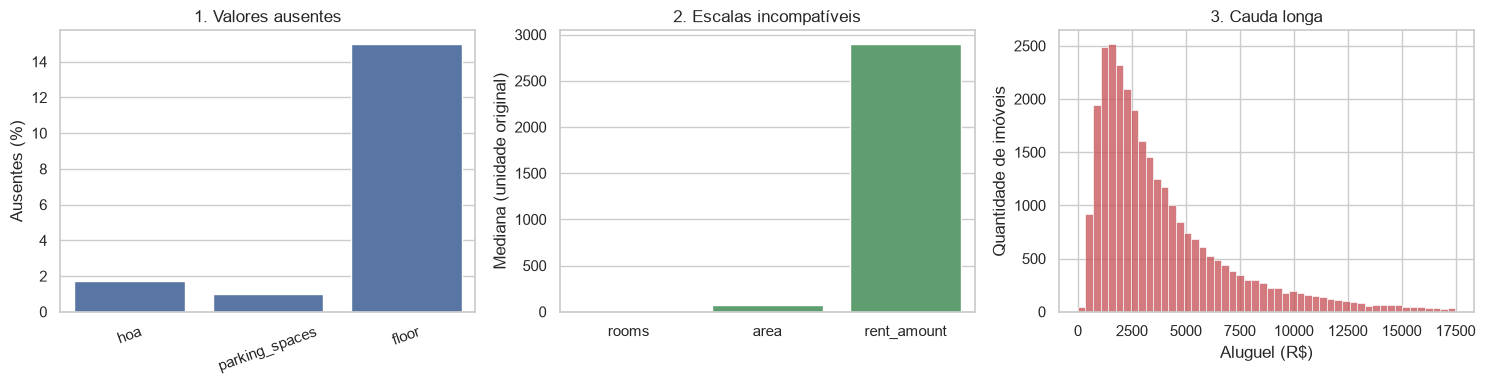

In [7]:
#2.Vamos montar a estrutura dos gráficos
# plt.subplots(1, 3): cria uma figura com 3 gráficos lado a lado (1 linha, 3 colunas)
# figsize=(15, 4): tamanho da figura em polegadas (largura 15, altura 4)
# devolve 2 objetos: fig (a figura inteira) e eixos (lista com os 3 espaços de desenho)
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))

#Painel 1: valores ausentes (barras)
sns.barplot(
    x=porcentagem_faltantes.index,      #nomes das colunas no eixo x
    y=porcentagem_faltantes.values,     #porcentagem de nulos no eixo y
    ax=eixos[0],                        #desenha no primeiro espaço (gráfico)
    color="#4C72B0",                  #azul
)
eixos[0].set(
    title="1. Valores ausentes",
    ylabel="Ausentes (%)",
    xlabel="",                          #sem nome no eixo x
)
eixos[0].tick_params(axis="x", rotation=20) #inclina os nomes do eixo x em 20 graus

#Painel 2: escalas incompatíveis (barras)
sns.barplot(
    x=medianas.index,                   #nomes das variáveis
    y=medianas.values,                  #mediana de cada uma
    ax=eixos[1],                        #desenha no segundo espaço
    color="#55A868",                  #verde
)
eixos[1].set(
    title="2. Escalas incompatíveis",
    ylabel="Mediana (unidade original)",
    xlabel="",
)

#Painel 3: cauda longa (histograma do aluguel)
sns.histplot(
    imoveis["rent_amount"],             #coluna a ser distribuída
    bins=50,                            #divide em 50 faixas
    binrange=(0, limite_aluguel),       #mostra só de 0 até o percentil 99
    ax=eixos[2],                        #desenha no terceiro espaço
    color="#C44E52",                  #vermelho
)
eixos[2].set(
    title="3. Cauda longa",
    xlabel="Aluguel (R$)",
    ylabel="Quantidade de imóveis",
)

plt.tight_layout()               # ajusta o espaçamento para nada ficar sobreposto
plt.show()                       # mostra a figura

- Valores ausentes. hoa e parking_spaces têm poucas lacunas (cerca de 2% e 1%), enquanto floor chega a 15%. Uma diferença tão grande sugere que a ausência em floor tem uma causa própria, investigada na seção 2.
- Escalas incompatíveis. O imóvel típico tem 2 quartos, cerca de 76 m² e aluguel de R$ 2.900. As três medianas estão separadas por ordens de grandeza, e o aluguel domina o painel apenas por causa da unidade.
- Cauda longa. Três quartos dos aluguéis ficam abaixo de cerca de R$ 5.100, mas a cauda se estende muito à direita. O maior aluguel chega a quase R$ 38 mil, bem além do recorte do gráfico. A média (cerca de R$ 4.000) fica acima da mediana, o mesmo padrão de assimetria positiva visto na Aula 5.

## 2.   Ausência Estrutural

Ao encontrar uma coluna com lacunas, é tentador preenchê-las imediatamente. Antes de escolher uma técnica, precisamos investigar por que o valor está ausente. Nem toda célula vazia representa erro de coleta ou perda de informação.

Na base de imóveis, floor e total_floors estão ausentes nas casas. Não houve falha de cadastro. Esses atributos descrevem a posição de uma unidade em um edifício e, portanto, não se aplicam a casas. Esse tipo de lacuna é chamado de ausência estrutural, pois decorre da definição da variável para determinado tipo de observação. Imputar um número produziria um valor sem referente real.

In [8]:
# Número de imóveis e proporção sem andar (floor nulo), por tipo de propriedade
(
    imoveis                                  #a tabela (a cadeia não a altera, só calcula um resultado)
    .groupby("property_type")                #separa a tabela em grupos: "casa" e "apartamento"
    .agg(                                    #agg: calcula uma ou mais estatísticas por grupo
        #nome_da_coluna_nova=("coluna_de_origem", "função")
        quantidade_imoveis=("property_type", "size"), #size: conta quantas linhas há em cada grupo
        proporcao_sem_andar=(   
            "floor",                         #coluna que será analisada em cada grupo
            lambda andar: (                  #função própria; andar é a coluna floor do grupo
                andar
                .isna()                      #True onde floor é nulo, False onde tem valor
                .mean()                      #média de True/False = proporção de nulos (0 a 1)
            ),
        ),
    )
)

,quantidade_imoveis,proporcao_sem_andar
property_type,,
apartamento,25024,0.0
casa,4415,1.0


Quando a ausência decorre de uma característica conhecida da observação, registre essa característica e não impute um valor numérico. Aqui, property_type torna explícita a informação que antes estava codificada apenas pela lacuna.

Depois de separar o caso estrutural, restam lacunas que podem representar informação perdida, como um aluguel não informado ou um número de vagas não registrado. Para esses casos, a imputação é uma alternativa possível. A escolha ainda depende do mecanismo que produziu a ausência e da quantidade de dados faltantes.

## 3.   Imputação: o impacto das alternativas

Imputar consiste em substituir um valor ausente por uma estimativa calculada a partir das informações disponíveis. Há estratégias simples, como usar uma medida de posição da própria coluna, e métodos multivariados, que estimam cada lacuna a partir de outras variáveis. Nesta aula, trabalharemos com estatísticas descritivas da Aula 5. Mesmo simples, essas estratégias permitem observar efeitos importantes, como concentração artificial de valores e redução da variabilidade.

Há uma dificuldade prática. Em uma lacuna real, o valor verdadeiro não foi observado. Sem uma referência, não podemos calcular diretamente o erro cometido pela imputação.

A saída é simular o problema:

1. partir de registros completos,
2. apagar alguns valores conhecidos,
3. imputar e comparar com o valor original.

Primeiro, a função que apaga uma fração dos valores e a base completa, que servirá de gabarito

Ou seja:

É uma simulação para testar métodos de preencher nulos. O problema: se você preenche um nulo real com a mediana, não tem como saber se acertou, porque o valor verdadeiro não existe. A solução é:

- Pegar uma base sem nulos (o gabarito, imoveis_true).
- Apagar valores de propósito, de forma aleatória (você sabe quais eram).
- Preencher com os métodos que quer comparar (média, mediana, por grupo).
- Comparar com o gabarito e ver qual método chegou mais perto.

In [9]:
# Função de apagamento e base-gabarito

# Gerador de números aleatórios. 42 é uma seed que garante que serão os mesmos resultados toda vez que você rodar
rng = np.random.default_rng(42)

def erase_at_random(values, share): #Apaga alguns valores da coluna, escolhidos por sorteio. O share diz quantos: 0.10 apaga cerca de 10%.
    return values.mask(rng.random(len(values)) < share)
    # values: uma coluna (Series) | share: fração a apagar (0.10 = 10%)
    # rng.random(len(values)): sorteia 1 número entre 0 e 1 para cada linha
    # (... < share): True nas linhas sorteadas (cerca de share% delas)
    # values.mask(cond): troca por NaN os valores onde cond é True; os demais ficam iguais

# Base-gabarito: só linhas completas em hoa e parking_spaces
imoveis_true = (
    imoveis                                       # tabela de partida (não é alterada)
    .dropna(subset=["hoa", "parking_spaces"])     # remove linhas com nulo NESSAS duas colunas
    .reset_index(drop=True)                       # renumera o índice de 0 em diante
)

Em seguida, criamos lacunas em três variáveis de tipos diferentes: discreta (valores separados, em saltos), contínua (valores em um intervalo, com decimais) e categórica (categorias, rótulos).

In [10]:
# Apaga valores em três colunas de tipos diferentes
imoveis_missing = (
    imoveis_true
    .assign(
        rooms=lambda df: erase_at_random(df["rooms"], .10),
        rent_amount=lambda df: erase_at_random(df["rent_amount"], .15),
        furniture=lambda df: erase_at_random(df["furniture"], .08),
    )
)

As proporções apagadas são 10% dos quartos, 15% dos aluguéis e 8% da mobília.

Conferimos quantos valores foram apagados:

In [11]:
# Quantidade e proporção de valores apagados por coluna
(
    imoveis_missing[["rooms", "rent_amount", "furniture"]] #seleciona essas 3 colunas do dataframe com lacunas
    .isna()                                     #True se nulo, False se não
    .sum()                                      #Soma das ocorrências de valores nulos em cada uma
    .to_frame("ausentes")                       #Resultado das somas posto em um df com coluna ausentes
    .assign(                                    #criação de nova coluna
        proporcao=lambda x: (                   #proporção = número de ausentes da coluna / tamanho (quantidade de valores) da coluna
            x.ausentes / len(imoveis_missing)
        ).round(3)                              #em até 3 casas decimais
    )
)

,ausentes,proporcao
rooms,2783,0.097
rent_amount,4308,0.150
furniture,2254,0.079


O apagamento simulado é completamente aleatório, mecanismo conhecido como MCAR (missing completely at random). Isso significa que a probabilidade de apagar uma célula não depende de nenhuma variável observada nem do próprio valor apagado.

Em dados reais, essa condição é forte e nem sempre plausível. A ausência pode estar associada ao próprio valor. Se imóveis caros anunciam “valor sob consulta” com maior frequência, por exemplo, a distribuição dos aluguéis observados deixa de representar a distribuição completa. Uma imputação baseada apenas nesses valores tende a subestimar os aluguéis omitidos.

### 3.1 Média, mediana e mediana agrupada

As estratégias mais simples substituem todas as lacunas por uma única constante calculada com os valores observados da coluna. A média utiliza toda a magnitude dos dados e, por isso, responde fortemente a valores extremos. A mediana depende apenas da ordenação e é mais resistente a caudas longas.

In [12]:
# Constantes para a imputação simples
rent_mean = (
    imoveis_missing.rent_amount
    .mean()
)

rent_median = (
    imoveis_missing.rent_amount
    .median()
)

A mediana por tier condiciona a estimativa ao padrão do imóvel. Cada lacuna recebe a mediana calculada entre os anúncios do mesmo grupo. Se um tier não tiver aluguéis observados, não será possível calcular sua mediana. Nesse caso, a mediana global funciona como estratégia de contingência.

In [13]:
# Imputação pela mediana de cada tier
rent_group = (
    imoveis_missing                             #tabela com lacunas
    .groupby("tier")                            #separa em grupos: affordable, mid, premium, luxury
    .rent_amount                                #pega a coluna rent_amount de cada grupo
    .transform(lambda x: x.fillna(x.median()))  #em cada grupo, preenche os nulos com a mediana DO GRUPO (do tier)
    .fillna(rent_median)                        #sobrou nulo (grupo sem nenhum aluguel)? usa a mediana global
)

O transform devolve uma resposta para cada linha da tabela original, na mesma ordem e com o mesmo índice. Nenhuma linha some e nenhuma é criada.
Se a tabela tem 1.000 linhas, o resultado tem 1.000 valores. O agg, ao contrário, daria só 4 valores (um por tier).

Cada valor do resultado fica no mesmo índice da linha de onde veio. O valor da linha 7 do resultado corresponde à linha 7 da tabela.

Como o resultado tem o mesmo tamanho e o mesmo índice, você consegue colocá-lo direto de volta na tabela, sem juntar nada, com o agg isso não poderia acontecer.

Reunimos as versões do aluguel para compará-las lado a lado:

In [14]:
# Versões do aluguel a comparar
rent_versions = {
    "Original": imoveis_true.rent_amount,
    "Com lacunas": imoveis_missing.rent_amount,
    "Média": imoveis_missing.rent_amount.fillna(rent_mean),
    "Mediana": imoveis_missing.rent_amount.fillna(rent_median),
    "Mediana por tier": rent_group,
}

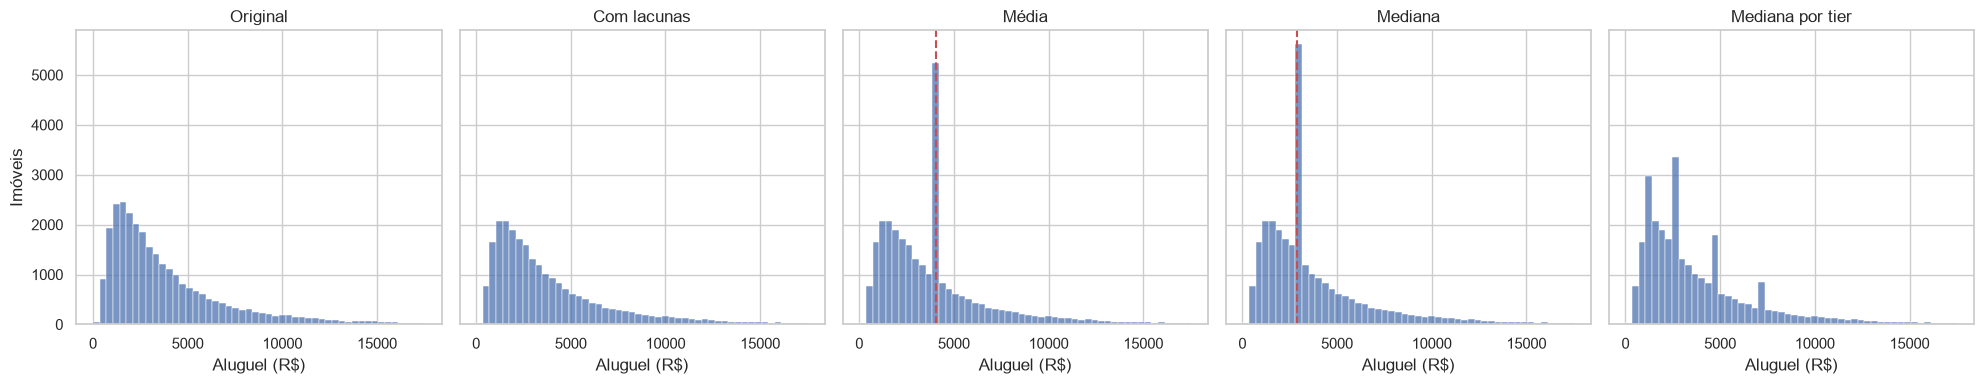

In [15]:
# Histograma de cada versão do aluguel 
# 1 linha, 5 painéis; sharey=True faz todos usarem a mesma escala no eixo y (facilita a comparação)
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

# Limite do eixo x: percentil 99 do aluguel verdadeiro, igual o gráfico feito anteriormente
limit = imoveis_true.rent_amount.quantile(.99)

# rent_versions é um dicionário: {"nome da versão": coluna de aluguel}
# .items() entrega cada par (nome, coluna); zip junta cada painel com um par
for ax, (label, values) in zip(axes, rent_versions.items()):
    sns.histplot(
        values.dropna(),          # dropna: o histograma não aceita NaN (as versões com lacunas têm)
        bins=50,                  # 50 faixas
        binrange=(0, limit),      # eixo x de 0 até o percentil 99
        ax=ax,                    # desenha neste painel
        color="#4C72B0",
    )
    ax.set(
        title=label,              # título do painel = nome da versão
        xlabel="Aluguel (R$)",
        ylabel="Imóveis",
    )
    # Só no painel "Média": linha vertical tracejada na média usada para preencher
    if label == "Média":
        ax.axvline(               # axvline: desenha uma linha vertical em x = rent_mean
            rent_mean,
            color="#C44E52",
            linestyle="--",
        )
    # Só no painel "Mediana": linha vertical tracejada na mediana usada para preencher
    if label == "Mediana":
        ax.axvline(
            rent_median,
            color="#C44E52",
            linestyle="--",
        )

plt.tight_layout()                # ajusta o espaçamento
plt.show()

Em vez de escrever cinco vezes o mesmo `sns.histplot`, o `for` repete o desenho uma vez por versão:

```python
for ax, (label, values) in zip(axes, rent_versions.items()):
```

| Peça | O que faz |
|---|---|
| `rent_versions.items()` | entrega os pares `("Original", série)`, `("Média", série)`... |
| `axes` | os 5 painéis, em ordem |
| `zip(axes, ...)` | junta o 1º painel com a 1ª versão, o 2º com a 2ª, e assim por diante |
| `ax, (label, values)` | desempacota: o painel, o nome e a coluna da vez |

Em cada volta, `ax` é o painel, `label` é o nome (vira o título) e `values` é a coluna de aluguel dessa versão.

- `sharey=True` mantém a mesma escala vertical em todos os painéis, por isso o pico da média ou da mediana aparece bem maior que as barras vizinhas.
- `values.dropna()` só é necessário para a versão "Com lacunas"; nas versões preenchidas não muda nada.
- Os `if label == ...` desenham a linha só nos painéis certos. Os nomes precisam ser **idênticos** aos do dicionário, inclusive maiúsculas e acentos, ou a linha não aparece.


Dois efeitos aparecem nos histogramas:

- média e mediana concentram todas as lacunas em um único valor, criando um pico artificial e reduzindo a dispersão,
- mediana por tier distribui as lacunas entre vários valores, um por grupo.

#### 3.1.1 Erro absoluto médio (MAE)
Os histogramas mostram como cada estratégia altera a **forma** da
distribuição, mas não dizem quão perto cada valor imputado ficou do
valor verdadeiro. Uma estratégia pode preservar bem o formato do
histograma e, ainda assim, errar muito imóvel a imóvel. Para avaliar a
**precisão** das estimativas, precisamos de uma métrica de erro. É aqui
que o gabarito se torna útil: como os valores foram apagados de
propósito, sabemos exatamente quanto cada lacuna deveria valer.

O erro de uma imputação é a diferença entre o valor verdadeiro $y_i$ e o
valor imputado $\hat{y}_i$. Essa diferença pode ser positiva ou
negativa, e uma média simples dos erros deixaria que subestimativas e
superestimativas se cancelassem, como a soma dos desvios em torno da
média na Aula 5. O **erro absoluto médio** (MAE, do inglês *mean
absolute error*) evita esse cancelamento ao tomar o valor absoluto de
cada erro antes de calcular a média:

$$
\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} \left| y_i - \hat{y}_i \right|
$$

Aqui, $n$ é o número de lacunas imputadas. O MAE é expresso na mesma
unidade da variável, o que facilita a interpretação: um MAE de R\$ 500
significa que, em média, a imputação errou o aluguel em R\$ 500, para
mais ou para menos.

Um exemplo pequeno ajuda a fixar o cálculo. Suponha três imóveis cujo
aluguel foi apagado e imputado com a mesma constante, R\$ 3.000:

| Imóvel | Verdadeiro ($y_i$) | Imputado ($\hat{y}_i$) | Erro absoluto |
|--------|--------------------|------------------------|---------------|
| A      | R\$ 2.000          | R\$ 3.000              | R\$ 1.000     |
| B      | R\$ 3.000          | R\$ 3.000              | R\$ 0         |
| C      | R\$ 10.000         | R\$ 3.000              | R\$ 7.000     |

O MAE é $(1.000 + 0 + 7.000)/3 \approx$ R\$ 2.666,67. Observe que um
único imóvel caro responde pela maior parte do erro.

Dois cuidados orientam o cálculo nesta seção:

-   **Apenas as posições imputadas entram na conta.** Nas posições
    observadas, o valor não foi alterado e o erro é zero por construção.
    Incluí-las reduziria artificialmente o MAE.
-   **A escolha da métrica favorece certas estratégias.** A mediana é o
    valor constante que minimiza a soma dos erros absolutos, enquanto a
    média minimiza a soma dos erros quadráticos. Por isso, entre as duas
    constantes, espera-se que a mediana apresente MAE menor, sobretudo
    em distribuições assimétricas como a do aluguel.

Primeiro, recuperamos no gabarito os valores verdadeiros das posições
apagadas:

In [16]:
# Posições apagadas e seus valores verdadeiros
# rent_missing: Series de True/False; True nas linhas em que o aluguel foi apagado (virou NaN)
rent_missing = imoveis_missing.rent_amount.isna()  

# .loc[linhas, coluna]: seleciona por RÓTULO do índice
#   - rent_missing (True/False): escolhe só as linhas marcadas como True (as apagadas)
#   - "rent_amount": escolhe a coluna
# Aplicado em imoveis_true (a base completa), devolve o valor VERDADEIRO dessas linhas
truth = imoveis_true.loc[rent_missing, "rent_amount"]

In [17]:
# MAE de cada estratégia, apenas nas posições imputadas
(
    pd.Series( #cria um series
        {
            "Média": ( #linha média
                (truth - rent_mean)
                .abs() #valor absoluto 
                .mean()
            ),
            "Mediana": ( #linha mediana
                (truth - rent_median)
                .abs()
                .mean()
            ),
            "Mediana por tier": ( #linha mediana por tier
                (truth - rent_group[rent_missing]) #o real - os valores faltantes por tier
                .abs()
                .mean()
            ),
        },
        name="MAE (R$)", #nome da coluna
    )
    .round(2) #duas casas decimais
    .to_frame() #visualização em dataframe
)

,MAE (R$)
Média,2505.30
Mediana,2313.52
Mediana por tier,1820.84


Quanto menor o MAE, menor foi o erro médio das imputações neste
experimento. Como esperado, a mediana erra menos que a média. A mediana
por `tier` reduz ainda mais o erro, porque usa uma informação adicional,
o padrão do imóvel, para aproximar a estimativa do valor verdadeiro.

Essa comparação avalia a precisão pontual sob o mecanismo MCAR simulado.
Ela não garante que a mesma estratégia seja adequada quando o padrão de
ausência dos dados reais for diferente.

#### 3.2 Moda e variáveis discretas

Para variáveis categóricas nominais, operações aritméticas como média e
mediana não têm interpretação válida. Uma alternativa simples é a moda,
isto é, a categoria observada com maior frequência.

Calculamos a categoria mais frequente de `furniture`:

In [18]:
# Categoria mais frequente de furniture
furniture_mode = (
    imoveis_missing.furniture
    .mode()
    .iloc[0] #caso tenha empate de valores (mais de uma moda), ele devolve o primeiro valor
)

furniture_mode

'not furnished'

Depois da imputação, todas as lacunas passam a contar como ocorrências
dessa categoria. A frequência da moda aumenta artificialmente, um efeito
que precisa ser considerado ao interpretar a distribuição resultante.

In [19]:
# Contagem das categorias antes e depois da imputação
(
    pd.concat(                                   #junta várias Series/tabelas
        {
            # o nome de cada chave desse dicionário vira o nome de uma coluna no resultado
            "Antes": imoveis_missing.furniture.value_counts(dropna=False),   # conta, incluindo os nulos
            "Depois da moda": (
                imoveis_missing.furniture
                .fillna(furniture_mode)          #preenche as lacunas com a categoria mais frequente
                .value_counts()                  #conta de novo (sem nulos)
            ),
        },
        axis=1,                                  #axis=1: junta lado a lado, como COLUNAS
    )
    .fillna(0)                                   #onde uma coluna não tem a categoria (NaN), coloca 0
)

,Antes,Depois da moda
furniture,,
not furnished,17265,19519.0
furnished,9122,9122.0
NaN,2254,0.0


Em uma variável quantitativa discreta, como o número de quartos, a média
é matematicamente definida, mas pode produzir um valor incompatível com
o domínio da variável, como uma quantidade fracionária de quartos:

In [20]:
# Média, mediana e moda do número de quartos
(
    pd.Series(
        {
            "média": imoveis_missing.rooms.mean(),
            "mediana": imoveis_missing.rooms.median(),
            "moda": (
                imoveis_missing.rooms
                .mode()
                .iloc[0]
            ),
        },
        name="quartos",
    )
    .to_frame()
)

,quartos
média,2.262085
mediana,2.000000
moda,2.000000


#### 3.3 Resumo da imputação

| Situação                      | Escolha inicial       |
|-------------------------------|-----------------------|
| Contínua e simétrica          | Média                 |
| Assimétrica ou com extremos   | Mediana               |
| Categórica ou discreta        | Moda ou mediana       |
| Varia entre grupos conhecidos | Estatística por grupo |

> **Important**
>
> Antes de imputar, crie uma **coluna indicadora** para distinguir
> valores observados de estimados.

> **E se um grupo não tiver observações?**
>
> Sua mediana será `NaN`. Use a mediana global como segunda opção. Mesmo
> quando existe algum valor observado, grupos muito pequenos produzem
> estimativas com alta variabilidade amostral.

Encerrada a comparação entre estratégias de imputação, passamos a outro
problema. As colunas são expressas em unidades e ordens de grandeza
diferentes. As duas próximas seções distinguem o escalonamento, que
modifica a representação numérica, das transformações não lineares, que
também alteram a forma da distribuição.

## 4. Escalonamento: a régua muda, a forma não

O termo **normalização** não tem uso inteiramente uniforme na literatura
e nas bibliotecas. Nesta seção, tratamos de **escalonamento**, isto é,
transformações afins do tipo $x' = (x - c)/s$. O parâmetro $c$
representa um centro, como média, mediana ou mínimo, e $s$ representa
uma medida de escala, como desvio-padrão, IQR ou amplitude. Essa
operação preserva a ordenação das observações. Também multiplica todas
as distâncias por uma mesma constante positiva, de modo que o formato do
histograma, a assimetria e a curtose não se alteram. Muda a unidade em
que a variável é representada.

O objetivo do escalonamento é colocar variáveis numéricas em escalas
comparáveis. Algoritmos que calculam distâncias, como k-vizinhos mais
próximos e k-médias, são diretamente sensíveis às magnitudes dos
atributos. Métodos ajustados por gradiente e modelos com regularização
também podem ser afetados. Sem escalonamento, uma variável de maior
ordem de grandeza pode dominar o cálculo apenas por causa de sua
unidade. A padronização por z-score e o escalonamento Min-Max são duas
alternativas conhecidas. O scikit-learn ainda reserva o nome
`Normalizer` para a normalização de cada amostra por sua norma vetorial,
uma operação diferente das três estudadas aqui. Por isso, convém
verificar a definição exata da técnica em vez de confiar apenas no termo
empregado.

Na base de imóveis, área em m², aluguel em reais e número de quartos têm
ordens de grandeza muito diferentes. Uma diferença de um quarto pode
distinguir substancialmente dois imóveis. Uma diferença de R\$ 1 no
aluguel costuma ser desprezível. O escalonamento permite que essas
diferenças sejam comparadas em unidades relativas à distribuição de cada
atributo.

### 4.1 Três escaladores

Os três escaladores diferem na escolha do centro e da escala, e essa
escolha determina a sensibilidade a valores extremos.

| Técnica | Centro e escala | Sensibilidade a extremos | Indicação |
|------------------|------------------|------------------|------------------|
| `StandardScaler` | Média e desvio-padrão | Alta | Sem extremos importantes |
| `RobustScaler` | Mediana e IQR | Baixa | Com valores extremos |
| `MinMaxScaler` | Mínimo e máximo | Muito alta | Limites estáveis |

Aplicamos os três escaladores ao aluguel.

Os escaladores do scikit-learn recebem um `DataFrame` e devolvem uma
matriz. `.ravel()` converte essa matriz em vetor.

In [21]:
# Aplica os três escaladores ao aluguel

# [["rent_amount"]] (colchetes duplos) devolve um DataFrame 2D (linha e colunas), colchetes simples retornam 1D; os scalers exigem entrada 2D
rent_frame = imoveis_true[["rent_amount"]]

# Dicionário: nome da versão -> valores do aluguel (original e escalados)
scaled = {
    "Original": rent_frame.rent_amount.to_numpy(),   # aluguel sem escalar, como array NumPy
    "StandardScaler": (
        StandardScaler()            # (x - média) / desvio padrão
        .fit_transform(rent_frame)  # fit: aprende média e desvio | transform: aplica
        .ravel()                    # array 2D (N, 1) -> lista simples de N valores
    ),
    "RobustScaler": (
        RobustScaler()              # (x - mediana) / IQR; menos sensível a outliers
        .fit_transform(rent_frame)
        .ravel()
    ),
    "MinMaxScaler": (
        MinMaxScaler()              # (x - mínimo) / (máximo - mínimo); resultado entre 0 e 1
        .fit_transform(rent_frame)
        .ravel()
    ),
}

Observe o eixo horizontal e a assimetria de cada painel:

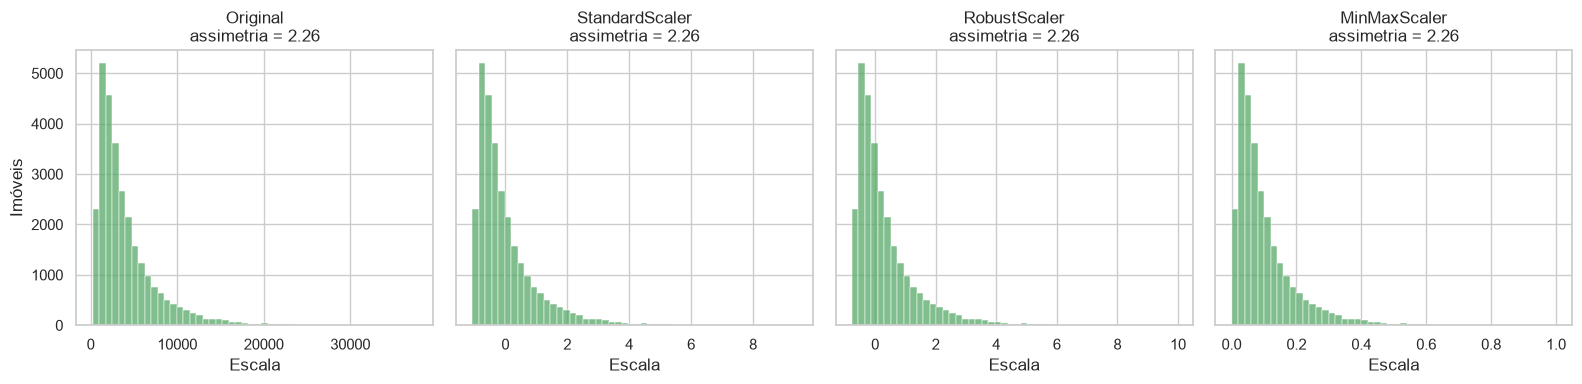

In [22]:
# Histograma do aluguel em cada escala
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True) #sharey=True faz todos os gráficos usarem o mesmo eixo y (a mesma escala vertical)

for ax, (label, values) in zip(axes, scaled.items()):
    sns.histplot(values, bins=50, ax=ax, color="#55A868")
    ax.set(
        title=f"{label}\nassimetria = {stats.skew(values):.2f}",
        xlabel="Escala",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

Os quatro histogramas têm a mesma forma e a mesma assimetria. Apenas os
valores do eixo horizontal mudam, porque cada método define uma nova
origem e uma nova unidade de medida.

### 4.2 Sensibilidade a extremos

O Min-Max usa o mínimo e o máximo observados como referências. Um único
aluguel extremo aumenta a amplitude usada no denominador e comprime os
demais valores em uma faixa estreita próxima de zero.

Para ver o efeito, acrescentamos um aluguel fictício de R\$ 500 mil e o
descartamos depois do ajuste:

In [23]:
# Min-Max ajustado com um aluguel fictício de R$ 500 mil

# Junta a coluna real com uma linha extra: um aluguel fictício de R$ 500.000
with_extreme = pd.concat(
    [rent_frame, pd.DataFrame({"rent_amount": [500_000.]})],  # tabela real + tabela de 1 linha
    ignore_index=True,    # renumera o índice (senão a linha extra repetiria um número já usado)
)

minmax_extreme = (
    MinMaxScaler()                   # (x - mínimo) / (máximo - mínimo)
    .fit_transform(with_extreme)     # o máximo agora é 500.000, por causa da linha fictícia
    .ravel()                         # array 2D (N+1, 1) -> lista simples de N+1 valores
    [:-1]                            # descarta o ÚLTIMO valor (o aluguel fictício); ficam só os reais
)

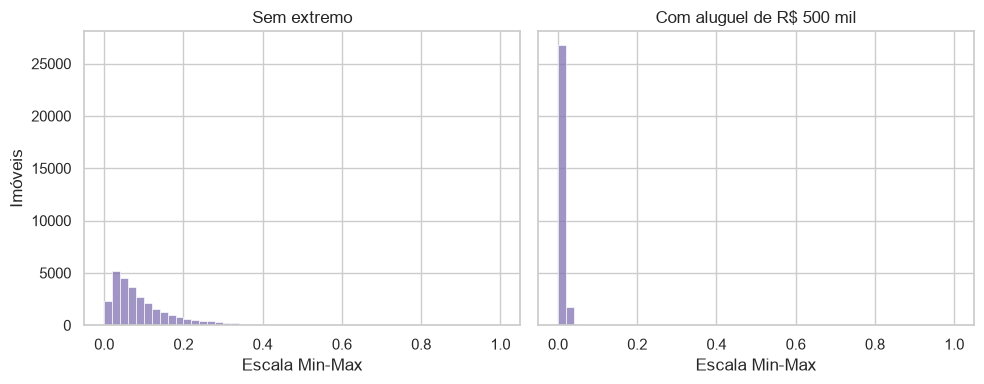

In [24]:
#Min-Max sem e com o valor extremo (dois histogramas lado a lado)

#1 linha, 2 painéis; sharey=True usa a mesma escala vertical nos dois, para comparar as alturas
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

#zip junta 3 listas, e o for pega um item de cada por volta:
#o painel (ax), os valores a desenhar (values) e o título (title)
for ax, values, title in zip(
    axes,
    [scaled["MinMaxScaler"], minmax_extreme],            #1º painel: sem extremo | 2º: com extremo
    ["Sem extremo", "Com aluguel de R$ 500 mil"],        #títulos de cada painel
):
    sns.histplot(
        values,
        bins=50,                 #50 faixas
        binrange=(0, 1),         #eixo x de 0 a 1 (a escala do Min-Max), igual nos dois painéis
        ax=ax,                   #desenha neste painel
        color="#8172B2",       #roxo
    )
    ax.set(
        title=title,
        xlabel="Escala Min-Max", #valores já escalados, entre 0 e 1
        ylabel="Imóveis",
    )

plt.tight_layout()               #ajusta o espaçamento
plt.show()

Com o extremo, quase todos os imóveis ficam concentrados no início da
escala. O `RobustScaler`, baseado na mediana e no IQR, é muito menos
sensível a esse efeito. O ponto extremo ainda permanece distante depois
da transformação, mas não determina o centro nem a escala usados para
representar a maioria das observações.

> **Important**
>
> **Escalonar muda a régua, não a forma.**

O escalonamento tornou as unidades comparáveis, mas o aluguel continua
com a mesma cauda longa observada na figura inicial. Poucos imóveis
muito caros ainda ocupam grande parte do eixo, enquanto a maioria dos
anúncios permanece concentrada à esquerda. Reduzir essa assimetria exige
uma transformação não linear.

## 5. Transformações: a forma muda

Esta seção trata do segundo sentido em que o termo **normalização**
aparece na literatura. Na seção 4, normalizar significava escalonar,
isto é, mudar a origem e a unidade de uma variável sem alterar sua
forma. Aqui, normalizar significa transformar a própria distribuição, em
geral para aproximá-la de uma forma mais simétrica e, em muitos casos,
mais próxima da distribuição normal, origem do nome. As duas operações
recebem o mesmo rótulo em textos e bibliotecas, mas produzem efeitos
diferentes sobre os dados. Por isso, ao encontrar o termo, convém
verificar qual dos dois sentidos está em jogo.

Nesta seção, usamos **transformação da distribuição** para designar a
aplicação de uma função não linear, como $\log(x)$ ou uma transformação
de potência. O objetivo pode ser reduzir a assimetria, estabilizar a
variância ou tornar uma relação multiplicativa mais próxima de uma
relação linear. Aproximar a variável de uma distribuição normal é uma
finalidade possível, mas não constitui uma exigência geral do
pré-processamento.

Ao contrário do escalonamento afim, uma função não linear comprime
regiões diferentes do eixo em intensidades diferentes. O logaritmo reduz
mais as distâncias entre valores altos do que entre valores baixos. Na
escala logarítmica, a distância entre R\$ 1.000 e R\$ 2.000 é igual à
distância entre R\$ 10.000 e R\$ 20.000, pois os dois pares representam
a mesma razão. A ordenação é preservada, mas as diferenças absolutas e
as razões entre distâncias mudam. Com isso, também podem mudar a
assimetria, a curtose e a influência de observações extremas.

Esse tipo de transformação é útil quando a escala original produz forte
heterogeneidade de variância, quando relações multiplicativas descrevem
melhor o fenômeno ou quando uma cauda longa exerce influência excessiva
sobre o ajuste. O custo aparece na interpretação. Um coeficiente ou uma
média calculados na escala transformada já não estão expressos
diretamente em reais. Transformações como Box-Cox e Yeo-Johnson ampliam
as possibilidades do logaritmo ao estimar, a partir dos dados, um
parâmetro de potência associado à aproximação da normalidade.

Quando o problema é a cauda longa, mudar a régua não basta. É preciso
mudar a **forma** da distribuição. A escolha da transformação depende
dos valores que a variável aceita: algumas exigem valores estritamente
positivos, outras aceitam zero ou até negativos.

### 5.1 Aluguel positivo: log e Box-Cox

Nesta base, todos os aluguéis são estritamente positivos, condição
necessária para aplicar `log` e Box-Cox. Começamos pelo logaritmo,
frequentemente adequado a valores monetários com variação
multiplicativa, e o comparamos com Box-Cox, que estima um parâmetro de
potência a partir dos dados.

`stats.boxcox` devolve os valores transformados e o λ estimado.

In [25]:
#Aluguel original, em log e em Box-Cox

#Coluna do aluguel da base-gabarito (uma Series)
rent = imoveis_true.rent_amount

#stats.boxcox: encontra o melhor expoente λ (lambda) para deixar a distribuição o mais simétrica possível
#devolve 2 coisas: os valores transformados e o λ escolhido
#exige valores ESTRITAMENTE positivos (> 0); aluguel é sempre positivo, então serve
boxcox_rent, boxcox_lambda = stats.boxcox(rent)

#Dicionário: nome da versão -> valores (para comparar depois)
rent_transformed = {
    "Original": rent,                                   #sem transformar
    "log": np.log(rent),                                #logaritmo natural: comprime a cauda direita
    f"Box-Cox (λ={boxcox_lambda:.2f})": boxcox_rent,    #f-string: o título já mostra o λ, com 2 casas
}

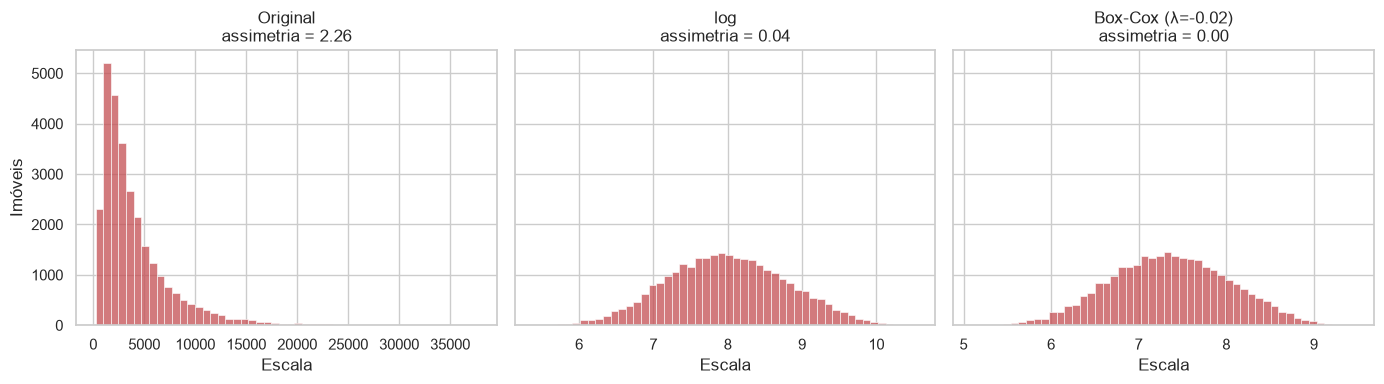

In [26]:
# Histogramas das transformações do aluguel
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, (label, values) in zip(axes, rent_transformed.items()):
    sns.histplot(values, bins=50, ax=ax, color="#C44E52")
    ax.set(
        title=f"{label}\nassimetria = {stats.skew(values):.2f}",
        xlabel="Escala",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

Box-Cox estima o parâmetro λ por máxima verossimilhança sob a hipótese
de que os valores transformados se aproximam de uma distribuição normal.
Quando λ = 0, sua definição corresponde ao logaritmo natural.

- (x^λ − 1) / λ      se λ ≠ 0
- log(x)             se λ = 0

O valor de λ próximo de zero mostra que, dentro da família Box-Cox, a
transformação estimada é muito semelhante ao logaritmo. Isso sustenta o
uso de `log` para o aluguel desta base.

Nem toda variável, porém, é estritamente positiva. Quando há zeros, o
logaritmo deixa de ser definido, e é preciso recorrer a variantes.

### 5.2 Distância com zeros: `log1p` e Yeo-Johnson

A distância ao transporte pode ser igual a zero para imóveis localizados
junto a uma estação. Como `log` e Box-Cox exigem valores estritamente
positivos, não podem ser aplicados diretamente. Duas alternativas são
`log1p`, que calcula $\log(1+x)$, e Yeo-Johnson, uma transformação de
potência definida também para zero e valores negativos.

Com `standardize=False`, o `PowerTransformer` apenas transforma, sem
escalonar.

In [27]:
# Distância original, em log1p e em Yeo-Johnson
transit = imoveis_true.transit_distance_min

pt = PowerTransformer(method="yeo-johnson", standardize=False)

transit_yj = (
    pt
    .fit_transform(imoveis_true[["transit_distance_min"]])
    .ravel()
)

transformed = {
    "Original": transit,
    "log1p": np.log1p(transit),
    f"Yeo-Johnson (λ={pt.lambdas_[0]:.2f})": transit_yj,
}

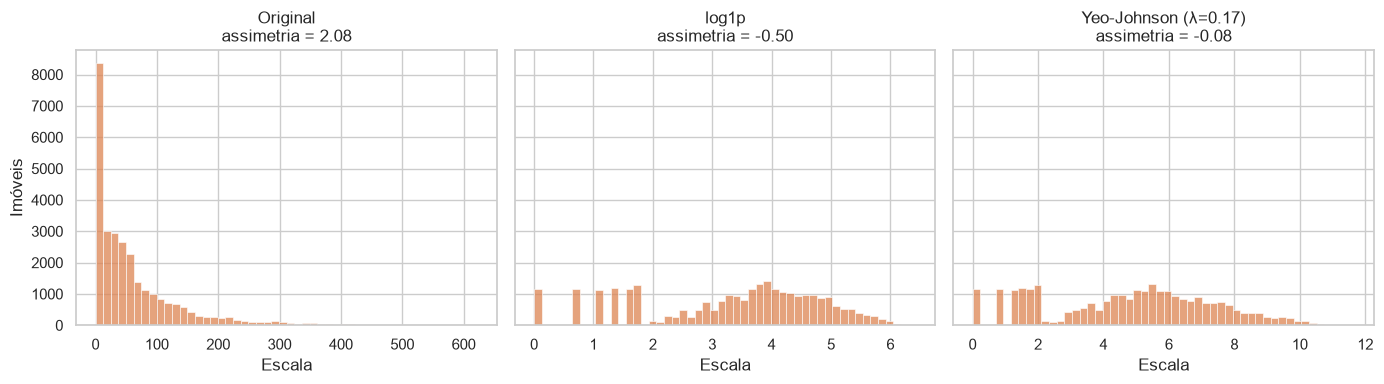

In [28]:
# Histogramas das transformações da distância
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, (label, values) in zip(axes, transformed.items()):
    sns.histplot(values, bins=50, ax=ax, color="#DD8452")
    ax.set(
        title=f"{label}\nassimetria = {stats.skew(values):.2f}",
        xlabel="Escala",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

Compare as assimetrias:

-   `log1p` aceita zeros, mas aqui comprime a cauda direita além do
    necessário,
-   Yeo-Johnson aceita qualquer sinal e estima uma transformação mais
    branda.

##3 5.3 Resumo das transformações

| Técnica     | Valores aceitos  | Interpretação                      |
|-------------|------------------|------------------------------------|
| `log`       | Positivos        | Boa: diferenças representam razões |
| `log1p`     | Zero e positivos | Boa, com inversa `expm1`           |
| Box-Cox     | Positivos        | Menos direta                       |
| Yeo-Johnson | Qualquer sinal   | Menos direta                       |

> **Fórmula e interpretação**
>
> A transformação de Box-Cox é dada por:
>
> $$
> x^{(\lambda)} =
> \begin{cases}
> \dfrac{x^\lambda - 1}{\lambda}, & \lambda \ne 0 \\[6pt]
> \log(x), & \lambda = 0
> \end{cases}
> $$
>
> Para voltar à unidade original:
>
> -   após `log`, use `np.exp`,
> -   após `log1p`, use `np.expm1`.

> **Important**
>
> **Transformar muda a forma.** A redução da assimetria deve ser
> avaliada junto com a perda de interpretação direta na unidade
> original.

Até aqui, cada técnica foi estudada isoladamente, em uma ou duas
variáveis e sobre a base de gabarito. Na prática, porém, as decisões são
aplicadas em conjunto e na ordem certa, sobre a base original, com suas
lacunas reais.

## 6. Aplicação e comparação final

Esta seção reúne as decisões anteriores em um único fluxo aplicado à
base completa. A ordem das operações importa. As colunas indicadoras
precisam ser criadas antes da imputação, enquanto as posições
originalmente ausentes ainda são identificáveis. A imputação precede as
transformações para que as medianas sejam calculadas e interpretadas na
unidade original.

Aplicamos as decisões em três etapas.

### 6.1 Registrar as lacunas

As colunas indicadoras são criadas **antes** da imputação. Depois dela,
o rastro se perderia.

In [29]:
# Colunas indicadoras das lacunas originais
imoveis_processed = (
    imoveis
    .assign(
        hoa_missing=lambda x: x.hoa.isna(), #por cada valor em hoa e vagas, verifique os nulos e coloque em colunas
        parking_spaces_missing=lambda x: x.parking_spaces.isna(),
    )
)

## 6.2 Imputar pela mediana do grupo

Os grupos combinam tipo de imóvel e `tier`. Grupos sem observações
recebem a mediana global.

In [30]:
# Imputa hoa e vagas pela mediana de cada grupo
groups = ["property_type", "tier"] #grupos que serão usado (apenas um colchete, retorna 1D)

imoveis_processed = (
    imoveis_processed
    .assign( #cria novas colunas
        hoa=lambda x: ( #por cada valor em hoa
            x
            .groupby(groups) #agrupe hoa pelos grupos
            .hoa
            .transform(lambda s: s.fillna(s.median())) #preenche os valores faltantes com a mediana DESSES grupos
            .fillna(imoveis.hoa.median()) #o restante é preenchido com a mediana global
        ),
        parking_spaces=lambda x: (
            x
            .groupby(groups)
            .parking_spaces
            .transform(lambda s: s.fillna(s.median()))
            .fillna(imoveis.parking_spaces.median())
        ),
    )
)

Conferimos que não restaram lacunas e quantos valores foram estimados:

In [31]:
# Lacunas restantes e valores estimados
(
    imoveis_processed
    .agg(
        {
            "hoa": lambda s: s.isna().sum(),
            "parking_spaces": lambda s: s.isna().sum(),
            "hoa_missing": "sum",
            "parking_spaces_missing": "sum",
        }
    )
)

hoa                         0
parking_spaces              0
hoa_missing               505
parking_spaces_missing    297
dtype: int64

### 6.3 Reduzir as caudas

Seguimos o resumo da seção 5.3:

-   área e valores monetários são positivos e recebem `log`,
-   a distância, que pode ser zero, recebe Yeo-Johnson.

In [32]:
# Log nas variáveis positivas e Yeo-Johnson na distância
imoveis_processed = (
    imoveis_processed
    .assign(
        area=lambda x: np.log(x.area),
        rent_amount=lambda x: np.log(x.rent_amount),
        property_tax=lambda x: np.log(x.property_tax),
        total=lambda x: np.log(x.total),
        transit_distance_min=lambda x: stats.yeojohnson(
            x.transit_distance_min
        )[0], # stats.yeojohnson devolve os valores transformados e o λ estimado. [0] seleciona os valores.
    )
)

### 6.4 Antes e depois

Comparamos as distribuições das cinco variáveis transformadas:

In [33]:
# Variáveis comparadas e seus rótulos nos gráficos
columns = [
    "area",
    "rent_amount",
    "property_tax",
    "total",
    "transit_distance_min",
]

labels = ["Área", "Aluguel", "IPTU", "Total", "Distância"]

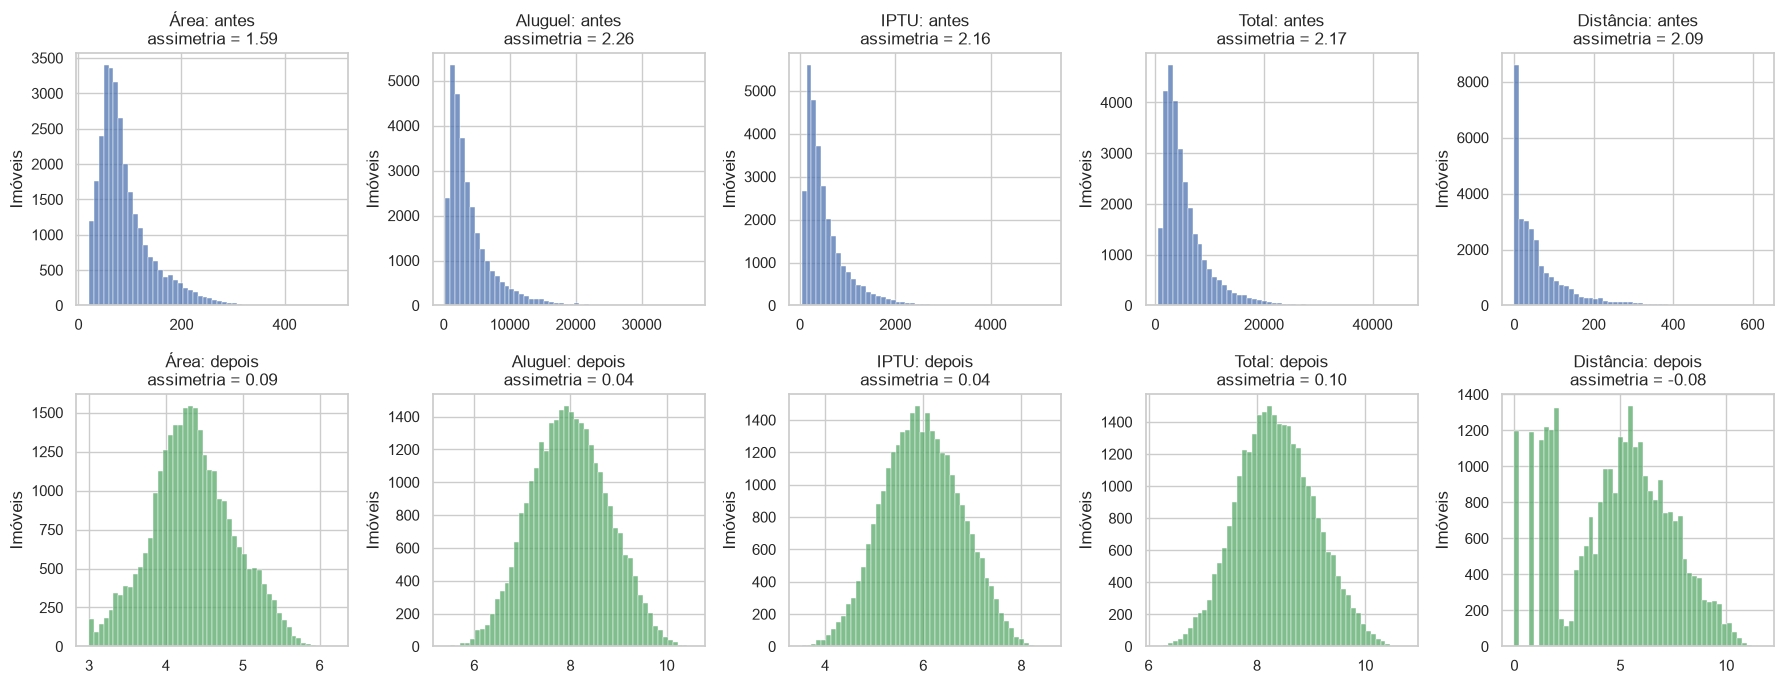

In [34]:
# Distribuições antes (linha de cima) e depois (linha de baixo)
fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for col, label, ax1, ax2 in zip(columns, labels, axes[0], axes[1]):
    before, after = imoveis[col], imoveis_processed[col]
    sns.histplot(before, bins=50, ax=ax1, color="#4C72B0")
    ax1.set(
        title=f"{label}: antes\nassimetria = {stats.skew(before):.2f}",
        xlabel="",
        ylabel="Imóveis",
    )
    sns.histplot(after, bins=50, ax=ax2, color="#55A868")
    ax2.set(
        title=f"{label}: depois\nassimetria = {stats.skew(after):.2f}",
        xlabel="",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

Na linha inferior, as distribuições apresentam menor assimetria, e os
valores extremos ocupam uma parcela menor do eixo. Isso não significa
que os extremos foram removidos. Suas distâncias em relação ao centro
foram comprimidas pela transformação.

> **Evite vazamento**
>
> Em um projeto de modelagem, os dados são divididos em treino e teste.
>
> Medianas, parâmetros λ e parâmetros dos escaladores devem ser
> estimados **apenas no conjunto de treino**. Em seguida, os mesmos
> valores estimados são aplicados ao conjunto de teste. Ajustá-los antes
> da separação permite que informações do teste influenciem o
> pré-processamento e produz vazamento de dados.

> **Extensão opcional: ydata-profiling**
>
> O relatório automático é útil para auditoria, mas não é necessário
> para o argumento visual da aula.
>
> ``` python
> # Relatório comparativo antes e depois do pré-processamento
> from ydata_profiling import ProfileReport, compare
>
> before = ProfileReport(
>     imoveis,
>     minimal=True,
> )
>
> after = ProfileReport(
>     imoveis_processed,
>     minimal=True,
> )
>
> (
>     compare([before, after])
>     .to_file(
>         "imoveis-sao-paulo/reports/comparacao_pre_processamento.html"
>     )
> )
> ```

## 7. Guia rápido

A tabela reúne as decisões discutidas no roteiro. Ela oferece critérios
iniciais, não regras automáticas. A escolha final depende do mecanismo
de ausência, da distribuição observada, do modelo empregado e do
objetivo da análise.

| Problema                         | Técnica                |
|----------------------------------|------------------------|
| Ausência estrutural              | Não imputar, registrar |
| Contínua simétrica               | Média                  |
| Assimétrica ou com extremos      | Mediana                |
| Categórica ou discreta           | Moda ou mediana        |
| Varia entre grupos               | Mediana por grupo      |
| Escalas diferentes, sem extremos | Z-score                |
| Escalas diferentes, com extremos | RobustScaler           |
| Limites estáveis                 | Min-Max                |
| Cauda positiva                   | Log ou Box-Cox         |
| Cauda com zeros                  | log1p ou Yeo-Johnson   |

### Síntese

Três classes de tratamento foram aplicadas à base de imóveis:

1.  **Imputação.** Nem toda ausência corresponde a um valor que deveria
    existir. Quando a imputação for apropriada, a estratégia deve
    considerar o tipo da variável, sua distribuição e as informações
    disponíveis em outros atributos. Uma coluna indicadora preserva o
    registro das posições estimadas.
2.  **Escalonamento.** Uma transformação afim altera a origem e a
    unidade da variável sem modificar a forma de sua distribuição. A
    presença de valores extremos influencia a escolha entre parâmetros
    convencionais, como média e desvio-padrão, e parâmetros robustos,
    como mediana e IQR.
3.  **Transformação.** Uma função não linear modifica as distâncias
    entre observações e pode reduzir a assimetria. Essa mudança pode
    favorecer a modelagem, mas exige cuidado ao interpretar e comunicar
    resultados na escala original.

## Perguntas para consolidar

**Pergunta 1: imputar sempre melhora a análise?**

A seção 2 mostrou lacunas que não deveriam ser preenchidas. Em que
situação uma estratégia com MAE baixo no experimento controlado ainda
pode piorar a análise quando aplicada à base real?

O MAE só mede o erro pontual em apagamentos aleatórios de valores que existem. Se na base real a ausência não é aleatória, ou é estrutural (o valor não existe), ou se o preenchimento distorce a distribuição, a estratégia pode piorar a análise mesmo com MAE baixo. O ideal é testar para cada coluna, onde o MAE escolherá o melhor caso dentro do cenário simulado, e depois comparar com a distribuição. Algo que funciona para um tipo de informação não funcionará em outra e pode não funcionar na distribuição real

> **Como pensar sobre isso**
>
> O MAE mede a distância entre valores imputados e valores verdadeiros
> nas posições apagadas artificialmente. Ele avalia o desempenho sob o
> mecanismo de ausência usado na simulação. Não demonstra que a variável
> seja aplicável a todas as observações nem que o mesmo padrão de
> ausência exista na base real.
>
> No caso do andar de uma casa, não existe valor verdadeiro a estimar,
> pois o atributo não se aplica à observação. O MAE nem sequer é uma
> métrica conceitualmente válida para esse caso. Em lacunas não
> estruturais, uma estratégia também pode apresentar baixo MAE sob MCAR
> e introduzir viés quando a ausência real depende do valor omitido.
> Imputações por constantes ainda reduzem a variabilidade observada e
> criam concentrações artificiais. Sem uma coluna indicadora, deixa de
> ser possível separar o que foi observado do que foi estimado.

**Pergunta 2: por que o `StandardScaler` não resolveu a assimetria?**

Na seção 4.1, os três escaladores produziram a mesma assimetria do
aluguel original. Por que isso acontece?

No escalonamento, apenas a régua da distribuição, ou seja, a forma que é medida, é alterada, sua forma original permanece a mesma. Os três escaladores aplicam uma transformação linear (subtraem uma constante e dividem por outra positiva), que altera a localização e a escala dos dados, mas preserva a forma da distribuição. A assimetria (forma da distribuição) fica inalterada. Para reduzi-la, é necessária uma transformação não linear, a qual comprime mais os valores grande do que os pequenos, que comprima a cauda longa.

> **Como pensar sobre isso**
>
> Os escaladores estudados aplicam uma transformação afim. Eles subtraem
> um centro e dividem por uma constante positiva. A operação desloca o
> eixo e multiplica todas as distâncias pela mesma constante.
>
> Como todas as distâncias são multiplicadas pelo mesmo fator, os
> momentos padronizados que definem assimetria e curtose permanecem
> iguais. Para mudar a forma, precisamos de uma transformação não
> linear, como `log` ou Box-Cox.

**Pergunta 3: qual escala você apresentaria ao gestor?**

O `log` reduziu fortemente a assimetria do aluguel. Você apresentaria ao
gestor um gráfico do aluguel em escala log?

Não apresentaria o log(aluguel) ao gestor. Apesar de reduzir a assimetria, os valores perdem a unidade e a interpretação (um eixo em log não é diretamente legível em reais, e distâncias passam a representar razões, não diferenças). Usaria o log como ferramenta de análise e apresentaria o histograma em escala logarítmica rotulada em reais, junto com a mediana e os quartis, que são interpretáveis e robustos à cauda longa.

> **Como pensar sobre isso**
>
> Depende do objetivo e do público. Para determinados modelos
> estatísticos, a escala transformada pode produzir relações mais
> lineares, variância mais estável ou menor influência da cauda.
>
> Para comunicação, a unidade original em reais costuma ser mais direta.
> Uma possibilidade é ajustar o modelo na escala logarítmica e converter
> previsões com `np.exp` antes de apresentá-las. Essa conversão exige
> atenção. A exponencial de uma previsão média na escala log não
> coincide, em geral, com a média condicional na escala original sem uma
> correção de retransformação.

## Para casa

1.  Compare o MAE da média e da mediana para `rooms` e relacione o
    resultado à assimetria e ao caráter discreto da variável.
2.  Impute o aluguel por `tier` e `zona`. Depois, use o bairro como
    grupo e discuta o efeito de grupos pequenos.
3.  Entre apartamentos, compare `log1p`, Box-Cox e Yeo-Johnson para
    `hoa`. Qual produz menor assimetria? Qual você apresentaria a um
    gestor?
4.  Antes de considerar o notebook pronto, use Restart Kernel and Run
    All.

> Escalonar muda a régua. Transformar muda a forma. Imputar muda os
> dados e deve deixar rastro.

1. Resposta:

In [35]:
#1.
# Constantes para a imputação simples (média e mediana de rooms com o dataset com lacunas)
rooms_mean = (
    imoveis_missing.rooms
    .mean()
)

rooms_median = (
    imoveis_missing.rooms
    .median()
)

In [36]:
# Posições apagadas e seus valores verdadeiros
rooms_missing = imoveis_missing.rooms.isna()  

# Aplicado em imoveis_true (a base completa), devolve o valor VERDADEIRO dessas linhas
rooms_truth = imoveis_true.loc[rooms_missing, "rooms"]

In [37]:
# MAE de cada estratégia, apenas nas posições imputadas
(
    pd.Series( #cria um series
        {
            "Média": ( #linha média
                (rooms_truth - rooms_mean)
                .abs() #valor absoluto 
                .mean()
            ),
            "Mediana": ( #linha mediana
                (rooms_truth - rooms_median)
                .abs()
                .mean()
            ),
        },
        name="MAE (R$)", #nome da coluna
    )
    .round(2) #duas casas decimais
    .to_frame() #visualização em dataframe
)

,MAE (R$)
Média,0.99
Mediana,0.93


In [38]:
print(rooms_mean)
print(rooms_median)

2.2620852347435996
2.0


In [39]:
imoveis_true.rooms.value_counts().sort_index()

rooms
0    2081
1    5657
2    9589
3    6924
4    3299
5     646
6     445
Name: count, dtype: int64

1. O MAE da mediana é menor que o da média, indicando que a média erra mais que a mediana, porém a diferença é baixa, elas erram quase o mesmo tanto. Ao verificar os valores da média e mediana, podemos ver que a média é, aproximadamente, 0,26 mais alta que a mediana, sugerindo que a distribuição tem uma assimetria positiva, mesmo que pequena, podendo ser vista pelo dado que há muitos imóveis com 0 a 3 quartos, e apenas poucos com 4 a 6. Como a coluna rooms é discreta e o MAE entre a média e a mediana é semelhante, no momento de escolha, a mediana, por devolver um valor inteiro, seria mais indicada no momento de preencher os valores faltantes.

2. Resposta:

In [40]:
# Imputação pela mediana de cada tier e zona
rent_group_test = (
    imoveis_missing                             
    .groupby(["tier", "zona"])                            
    .rent_amount                                #pega a coluna rent_amount de cada grupo
    .transform(lambda x: x.fillna(x.median()))  
    .fillna(rent_median)                        #sobrou nulo (grupo sem nenhum aluguel)? usa a mediana global
)

bairro_group = (
    imoveis_missing                             
    .groupby("bairro")                            
    .rent_amount                                
    .transform(lambda x: x.fillna(x.median()))  
    .fillna(rent_median)   
)

In [41]:
# MAE de cada estratégia, apenas nas posições imputadas
(
    pd.Series( #cria um series
        {
            "Média": ( #linha média
                (truth - rent_mean)
                .abs() #valor absoluto 
                .mean()
            ),
            "Mediana": ( #linha mediana
                (truth - rent_median)
                .abs()
                .mean()
            ),
            "Mediana por tier" : (
                (truth - rent_group[rent_missing])
                .abs()
                .mean()
            ),
            "Mediana por tier e zona": ( #linha mediana por tier
                (truth - rent_group_test[rent_missing]) #o real - os valores faltantes por tier
                .abs()
                .mean()
            ),
            "Mediana por bairro" : (
                (truth - bairro_group[rent_missing])
                .abs()
                .mean()
            ),
        },
        name="MAE (R$)", #nome da coluna
    )
    .round(2) #duas casas decimais
    .to_frame() #visualização em dataframe
)

,MAE (R$)
Média,2505.30
Mediana,2313.52
Mediana por tier,1820.84
Mediana por tier e zona,1800.94
Mediana por bairro,1748.06


In [42]:
imoveis.groupby("tier").rent_amount.median()

tier
affordable    1340.0
luxury        7280.0
mid           2480.0
premium       4540.0
Name: rent_amount, dtype: float64

In [43]:
imoveis.groupby(["tier","zona"]).rent_amount.median().unstack()

zona,Centro,Zona Leste,Zona Norte,Zona Oeste,Zona Sul
tier,,,,,
affordable,1780.00,1290.0,1320.0,NaN,1360.0
luxury,6275.00,NaN,NaN,7390.00,7630.0
mid,2761.23,2160.0,2025.0,2520.00,2970.0
premium,4345.00,4355.0,NaN,4693.35,4710.0


In [44]:
imoveis_missing.groupby("bairro").rent_amount.count()

bairro
Aclimação              238
Alto de Pinheiros      305
Anália Franco          276
Aricanduva             300
Barra Funda            299
                      ... 
Vila Mariana           256
Vila Nova Conceição    259
Vila Olímpia           285
Vila Prudente          296
Vila Sônia             267
Name: rent_amount, Length: 85, dtype: int64

2. O MAE tende a baixar de acordo com o quão específico você for em relação ao valor que quer imputar, e o quão diferente as medianas ou médias são de acordo com a especificação que você está usando. A média geral, por ser sensível a valores extremos, tende a errar mais que a mediana, a qual é mais robusta. Restringindo a mediana por tier, podemos ver que a diferença da mediana entre tiers é grande, o que faz o MAE diminuir, já que estremos preenchendo o valor do aluguel por grupos. Ao reduzir por tier e zona, a diferença não diminui tanto, pois as medianas entre os tiers das zonas não são muito diferentes entre si. Fazendo a mediana por bairro, aumentamos a especificidade ainda mais, pois agora a diferença entre as medianas vão levar em conta o tipo de construção de cada bairro e valor dos imóveis de cada um. Comparando com as zonas, as zonas englobam vários bairros, alguns mais periféricos e outros mais luxuosos, já os bairros são bem divididos entre si, onde cada um possui seu tipo de imóvel e valores mais semelhantes.

3. Resposta:

In [45]:
# Distância original, em log1p e em Yeo-Johnson
apartamentos = imoveis_true.loc[imoveis_true["property_type"] == "apartamento"]

hoa = apartamentos.hoa

pt = PowerTransformer(method="yeo-johnson", standardize=False)
pt2 = PowerTransformer(method="box-cox", standardize=False)

hoa_yj = (
    pt
    .fit_transform(apartamentos[["hoa"]])
    .ravel()
)

hoa_bc = (
    pt2
    .fit_transform(apartamentos[["hoa"]])
    .ravel()
)

transformed = {
    "Original": hoa,
    "log1p": np.log1p(hoa),
    f"Yeo-Johnson (λ={pt.lambdas_[0]:.2f})": hoa_yj,
    f"Box-Cox (λ={pt2.lambdas_[0]:.2f})": hoa_bc,
}

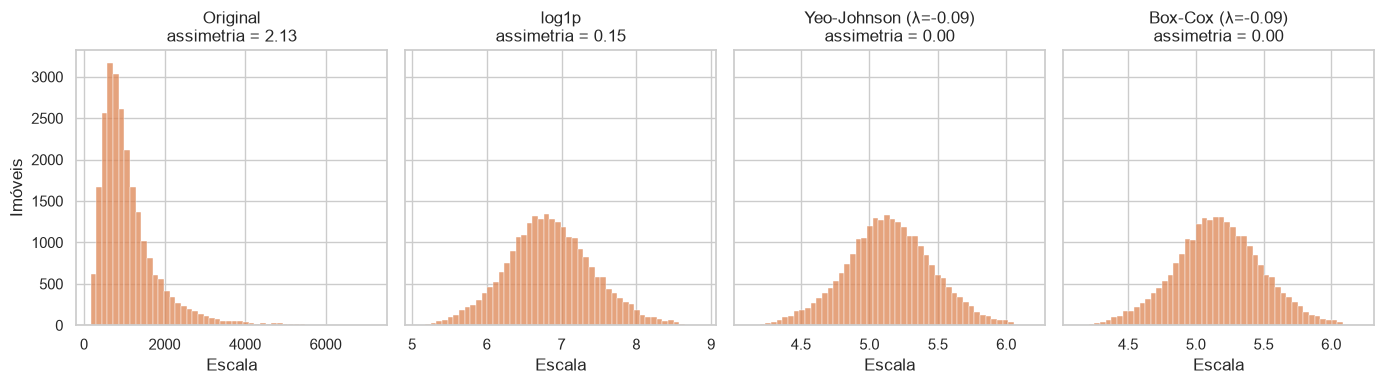

In [46]:
# Histogramas das transformações da distância
fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharey=True)

for ax, (label, values) in zip(axes, transformed.items()):
    sns.histplot(values, bins=50, ax=ax, color="#DD8452")
    ax.set(
        title=f"{label}\nassimetria = {stats.skew(values):.2f}",
        xlabel="Escala",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

3. Entre as transformações aplicadas à taxa de condomínio (hoa), o Box-Cox e o Yeo-Johnson produzem a menor assimetria, atingindo 0.00, enquanto o log1p alcança 0.15. Para apresentar a um gestor, a escolha ideal seria o log1p. Embora o Box-Cox e o Yeo-Johnson tenham uma vantagem na eliminação da assimetria, a transformação logarítmica é consolidada no mercado, o que facilita a comunicação e dispensa a necessidade de explicar coisas a mais, como o expoente lambda.